# 070 CASE 140 — Super-resolution: central Stockholm

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) with
> [IMINT Engine](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine). Not a validated product or service, and without support.

**Question:** How much detail can a super-resolution model add to a 10 m Sentinel-2 image?

**Area:** Gamla stan and Riddarholmen, central Stockholm, 4 July 2025.

**Partners:** RISE

**Data:** Copernicus Sentinel-2 L2A from [Digital Earth Sweden](https://digitalearth.se),
fetched through its openEO API.

**Licence:** The notebook is Apache-2.0 like the repository's code; its saved outputs are CC0 1.0 (see [License](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine#license)). Contains modified Copernicus Sentinel data 2025. SEN2SR model and package from ESA OpenSR, CC0 1.0.

## Before you run

Install IMINT Engine at the commit these results were produced with, plus Jupyter and the plotting
libraries:

```bash
pip install "imint-engine[fetch,inference] @ git+https://github.com/DigitalEarthSwedenExperimentalLab/imintengine@b183e1abd4653cb843a75557b05c09915fb85904" jupyterlab folium matplotlib sen2sr==0.8.5 mlstac==0.4.9
```

The notebook reads Sentinel-2 from Digital Earth Sweden, so each user logs in with their own DES
account in the *Log in* cell below, either with EGI in the browser or with a DES username and
password; see [digitalearth.se](https://digitalearth.se) for access. Every data fetch goes through
that login, nothing is saved in the notebook, and without a login the fetch stops with an error.
There is no synthetic fallback: every figure comes from real Sentinel-2 data. A run takes about three minutes.

## Log in to Digital Earth Sweden

In [ ]:
from getpass import getpass

import imint.fetch
import openeo
from IPython.display import clear_output

# Log in with your own Digital Earth Sweden account. Choose one:
#   "egi"      - your EGI account in the browser: open the link shown here and enter the code
#   "password" - your DES username and password, typed when asked
LOGIN_METHOD = "egi"

des = openeo.connect("https://openeo.digitalearth.se")
if LOGIN_METHOD == "password":
    user, password = input("DES username: "), getpass("DES password: ")
    if not (user and password):
        raise ValueError("enter both a DES username and a password")
    des.authenticate_basic(user, password)
    del password
else:
    des.authenticate_oidc(provider_id="egi")

# Every IMINT Engine fetch below uses this login and no other credentials on the machine
# (the pinned engine has no public parameter for a connection yet).
imint.fetch._connect = lambda token=None, token_path=None: des
clear_output()  # keep the typed username and the login link out of a saved notebook
print("Logged in to Digital Earth Sweden.")


## 1. Method

```
AOI + date → fetch_des_data → 2.56 km crop → bicubic ×4 and SEN2SR ×4 (2.5 m pixels) → compare
```

SEN2SR (ESA OpenSR) is a convolutional network trained to turn 10 m Sentinel-2 bands into 2.5 m
images while keeping the reflectance consistent with the original. Bicubic interpolation is the
baseline: it makes the pixels smaller without adding detail. IMINT Engine also wraps OpenSR's latent
diffusion model (LDSR), which needs a GPU and is left out here.

## 2. Area and data

The map is interactive when the notebook runs in Jupyter; GitHub's viewer shows only a placeholder for it.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import folium

from imint.fetch import fetch_des_data


def load_scene(date, aoi, max_cloud=0.3):
    """Fetch one Sentinel-2 L2A scene from Digital Earth Sweden with your login (no fallback)."""
    scene = fetch_des_data(date=date, coords=aoi, cloud_threshold=max_cloud)
    nodata = np.all(np.stack([a == 0 for a in scene.bands.values()]), axis=0)
    if nodata.mean() > 0.01:  # the archive sometimes holds only part of a scene
        raise ValueError(f"{date}: {nodata.mean():.0%} of the area has no data in this DES scene; use another date")
    land = np.isin(scene.scl, [4, 5])  # cloud-free vegetation and bare soil
    if land.any():
        empty = [b for b, a in scene.bands.items() if (a[land] == 0).mean() > 0.05]
        if empty:  # some archived scenes have bands missing; never analyse them
            raise ValueError(f"{date}: bands {empty} are empty over land in this DES scene; use another date")
    h, w = scene.rgb.shape[:2]
    print(f"{date}: {len(scene.bands)} bands, {h} x {w} px at 10 m, "
          f"cloud and shadow {scene.cloud_fraction:.1%} (SCL), CRS {scene.geo.crs}")
    return scene

AOI = {"west": 18.0169, "south": 59.2953, "east": 18.1244, "north": 59.3768}  # central Stockholm
DATE = "2025-07-04"

scene = load_scene(DATE, AOI)

    Cloud fraction: 0.0%
2025-07-04: 11 bands, 936 x 654 px at 10 m, cloud and shadow 0.0% (SCL), CRS EPSG:3006


In [3]:
center = [(AOI["south"] + AOI["north"]) / 2, (AOI["west"] + AOI["east"]) / 2]
m = folium.Map(location=center, zoom_start=12, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Satellite basemap",
).add_to(m)
folium.Rectangle(
    bounds=[[AOI["south"], AOI["west"]], [AOI["north"], AOI["east"]]],
    color="#e8590c", weight=2, fill=False, popup="Stockholm",
).add_to(m)
folium.LayerControl().add_to(m)
m

## 3. Super-resolve a 2.56 km crop

In [4]:
import contextlib
import io
from pyproj import Transformer
from imint.analyzers.sr import BicubicSR, SEN2SR

BANDS = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"]
x, y = Transformer.from_crs("EPSG:4326", scene.geo.crs, always_xy=True).transform(18.068, 59.325)
col, row = (int(v) for v in ~scene.geo.transform * (x, y))  # Gamla stan
r0, c0 = row - 128, col - 128
x10 = np.stack([scene.bands[b][r0:r0 + 256, c0:c0 + 256] for b in BANDS])

with contextlib.redirect_stderr(io.StringIO()):  # the first run downloads the model (9 MB)
    sen2sr = SEN2SR({"device": "cpu"}).predict(x10)
bicubic = BicubicSR({}).predict(np.moveaxis(x10[[2, 1, 0]], 0, -1))
for r in (bicubic, sen2sr):
    print(f"{r.model:8s} success={r.success} {r.error or ''} output {r.sr.shape if r.success else '-'}")

bicubic  success=True  output (1024, 1024, 3)
sen2sr   success=True  output (1024, 1024, 3)


## 4. Results

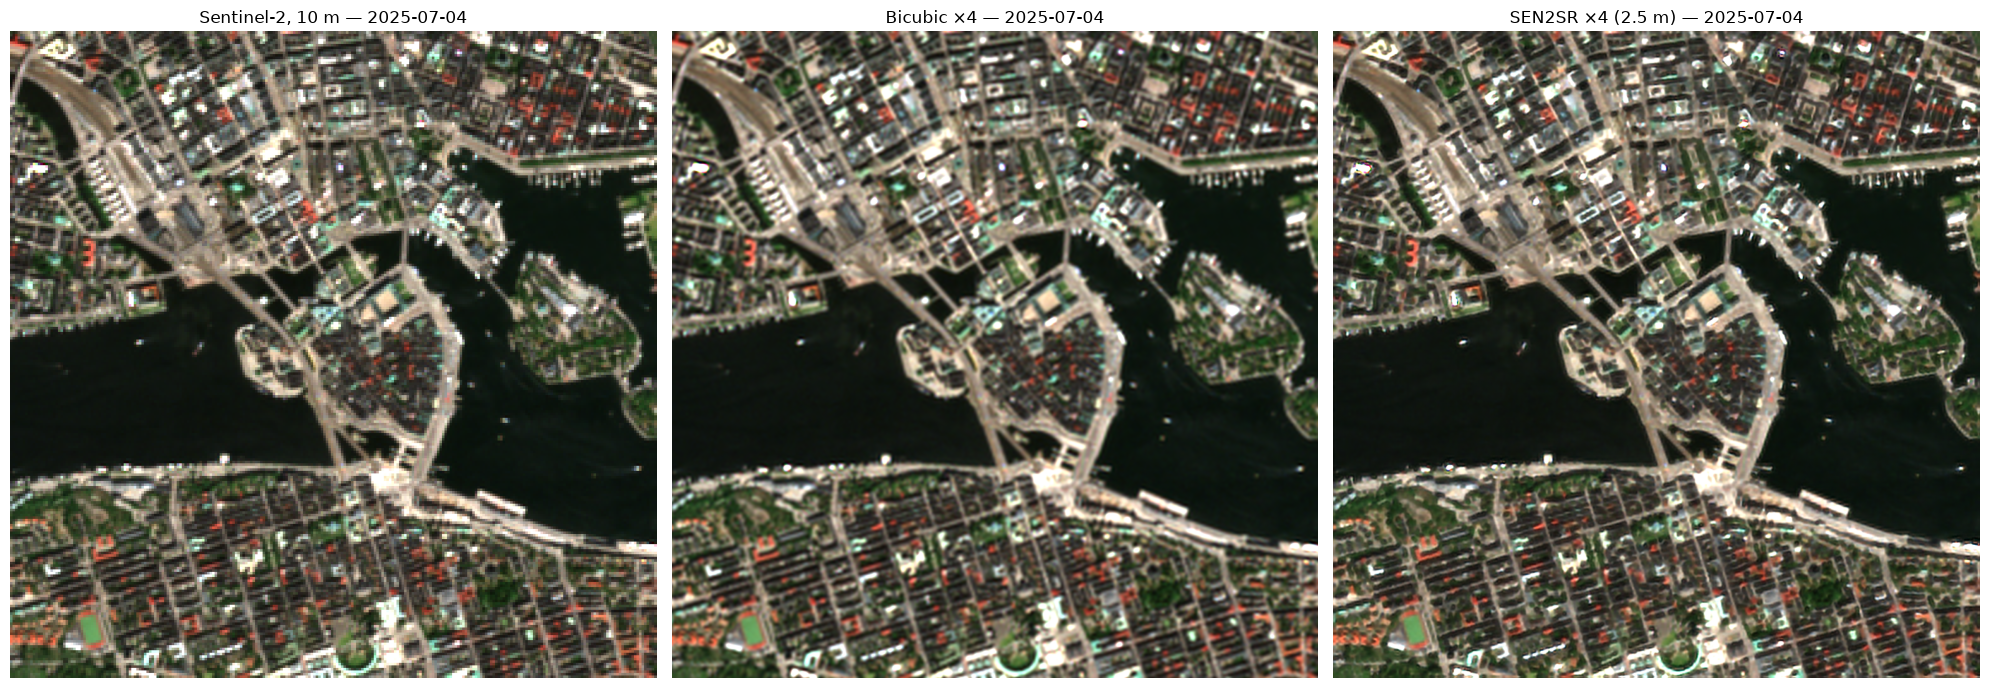

In [5]:
show = lambda a: np.clip(a / 0.2, 0, 1)
original = np.repeat(np.repeat(np.moveaxis(x10[[2, 1, 0]], 0, -1), 4, axis=0), 4, axis=1)
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, img, title in [(axes[0], original, "Sentinel-2, 10 m"), (axes[1], bicubic.sr, "Bicubic ×4"),
                       (axes[2], sen2sr.sr, "SEN2SR ×4 (2.5 m)")]:
    ax.imshow(show(img)); ax.set_title(f"{title} — {DATE}"); ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Interpretation

Super-resolution sharpens edges such as quays, bridges and street blocks by adding detail the model
learned from training pairs of satellite and aerial images. It cannot show what the 10 m pixels did
not record: small objects and text-like patterns are guesses. Use it for visual interpretation, not
for measuring things smaller than the original pixels.

**Links:** [`imint/analyzers/sr`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/analyzers/sr) ·
[SEN2SR](https://github.com/ESAOpenSR/sen2sr)

## Provenance

The saved outputs were produced by running this notebook top to bottom against IMINT Engine commit [`b183e1a`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/commit/b183e1abd4653cb843a75557b05c09915fb85904) with data from Digital Earth Sweden. Dates are acquisition dates, chosen among the scenes DES holds by the cloud fraction over the area in the scene classification (SCL).